# Publisher Diversity Re-Ranking Component
## Phase 2: Beyond the Feed — Diversity-Aware News Recommendation

**Component:** Publisher Diversity Re-ranking  
**Algorithm:** Publisher-Aware Maximal Marginal Relevance (MMR) with Source Concentration Penalty  
**Dataset:** Cleaned GDELT News Corpus (15,395 articles, 2,117 unique publishers)  
**Deliverable:** Suraiya's Phase 2 Individual Component (`phase2_publisher_diversity.ipynb`)  
**Baseline Reference:** `phase2_baseline_recommendation.ipynb`

---

### Objective & Architectural Context

In Phase 1 of our global news analysis, we identified that content-based greedy recommendation systems inadvertently induce severe media concentration:
- Dominant high-volume news organizations (such as `iheart.com`, `indiatimes.com`, `aol.co.uk`) produce large volumes of articles across popular themes.
- When recommendations are sorted purely by topic relevance score, articles from the same publisher repeatedly occupy multiple slots in the user's feed.
- For example, in baseline recommendations for our benchmark **Health Researcher** profile, two publishers (`iheart.com` and `irishexaminer.com`) each capture multiple top-10 slots, capping publisher diversity at only **8 out of 10** distinct sources.

This component implements the **Publisher Diversity Re-ranking module** (Stage 3C in our team architecture). Using an adapted **Maximal Marginal Relevance (MMR)** formulation, it penalizes publisher redundancy relative to articles already selected in the recommendation slate. This guarantees source pluralism, lowers the Herfindahl-Hirschman Index (HHI), and introduces fresh editorial perspectives while retaining high user topic relevance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Optional, Tuple, Set, Any
from pathlib import Path

# Configure display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 60)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Data Ingestion & Dataset Audit

We ingest `data/gdelt_clean.csv` using strict missing-value handling (`keep_default_na=False`) to avoid interpreting missing tokens as empty strings or accidental diversity categories. We inspect the overall volume and publisher distribution across the 15,395 articles.

In [2]:
data_path = Path("../data/gdelt_clean.csv")
df = pd.read_csv(data_path, keep_default_na=False)

print(f"Dataset shape: {df.shape}")
print(f"Total articles: {len(df):,}")
print(f"Total unique publishers: {df['publisher'].nunique():,}")

top_15_publishers = df['publisher'].value_counts().head(15)
print("\nTop 15 Publishers by Volume:")
for rank, (pub, count) in enumerate(top_15_publishers.items(), 1):
    pct = (count / len(df)) * 100
    print(f"  {rank:2d}. {pub:<30} {count:5d} articles ({pct:5.2f}%)")

Dataset shape: (15395, 14)
Total articles: 15,395
Total unique publishers: 2,117

Top 15 Publishers by Volume:
   1. iheart.com                       263 articles ( 1.71%)
   2. indiatimes.com                   254 articles ( 1.65%)
   3. aol.co.uk                        173 articles ( 1.12%)
   4. manilatimes.net                  159 articles ( 1.03%)
   5. aol.com                          153 articles ( 0.99%)
   6. themarketsdaily.com              138 articles ( 0.90%)
   7. prokerala.com                    134 articles ( 0.87%)
   8. finanznachrichten.de             121 articles ( 0.79%)
   9. freepressjournal.in              118 articles ( 0.77%)
  10. tickerreport.com                 117 articles ( 0.76%)
  11. yahoo.com                        112 articles ( 0.73%)
  12. dailypolitical.com               100 articles ( 0.65%)
  13. hindustantimes.com                89 articles ( 0.58%)
  14. jpost.com                         88 articles ( 0.57%)
  15. moneycontrol.com             

## 2. Topic Taxonomy & Selectable Topics

We parse the semicolon-delimited `topic` strings into individual list elements and identify the selectable topic taxonomy, excluding `Unknown` and `Other` categories from user-driven relevance calculations.

In [3]:
df["topic_list"] = df["topic"].apply(
    lambda x: [t.strip() for t in x.split(";") if t.strip()]
)

all_topics = sorted({
    topic for topics in df["topic_list"] for topic in topics
})

selectable_topics = sorted(set(all_topics) - {"Unknown", "Other"})

print(f"Total unique topics: {len(all_topics)}")
print(f"Selectable topics for user preference ({len(selectable_topics)}):")
for t in selectable_topics:
    print(f" - {t}")

Total unique topics: 11
Selectable topics for user preference (9):
 - Business and Economy
 - Conflict and Security
 - Education
 - Environment and Climate
 - Health
 - Politics and Government
 - Science
 - Society and Culture
 - Technology


## 3. Reusable Baseline Relevance Scoring

As mandated in Section 3 of the Phase 2 requirements, both diversity implementations must use the **exact baseline relevance scoring method without modification**. Topic relevance is defined as the arithmetic mean of user preference weights across the article's valid topics:

$$\mathrm{Rel}(u, a) = \frac{1}{|V_a|} \sum_{t \in V_a} u(t)$$

where $V_a$ is the set of valid topics for article $a$, and $u(t)$ is the user's preference weight for topic $t$.

In [4]:
def calculate_relevance(topic_list: List[str], user_profile: Dict[str, float]) -> float:
    """
    Calculate baseline arithmetic mean relevance across valid topics.
    Excludes 'Unknown' and 'Other' categories.
    """
    valid_topics = [t for t in topic_list if t not in {"Unknown", "Other"}]
    if not valid_topics:
        return 0.0
    scores = [user_profile.get(t, 0.0) for t in valid_topics]
    return float(sum(scores) / len(scores))


def score_all_candidates(df: pd.DataFrame, user_profile: Dict[str, float]) -> pd.DataFrame:
    """
    Score all articles against user topic preferences and retain positive candidates.
    """
    scored = df.copy()
    scored["relevance_score"] = scored["topic_list"].apply(
        lambda topics: calculate_relevance(topics, user_profile)
    )
    return scored[scored["relevance_score"] > 0].copy()

print("Baseline scoring functions verified and ready.")

Baseline scoring functions verified and ready.


## 4. Benchmark User Profiles

To ensure experimental rigor and enable direct side-by-side comparison between the Baseline, Shahida's Geographic Diversity component, and Suraiya's Publisher Diversity component, we evaluate against the team's standardized benchmark profiles:

1. **Tech Enthusiast:** `Technology: 0.8`, `Business and Economy: 0.6`, `Health: 0.2`
2. **Environment Explorer:** `Environment and Climate: 0.9`, `Science: 0.7`, `Technology: 0.3`
3. **Health Researcher:** `Health: 0.9`, `Science: 0.8`, `Education: 0.4`

In [5]:
user_profiles = {
    "Tech Enthusiast": {
        "Technology": 0.8,
        "Business and Economy": 0.6,
        "Health": 0.2
    },
    "Environment Explorer": {
        "Environment and Climate": 0.9,
        "Science": 0.7,
        "Technology": 0.3
    },
    "Health Researcher": {
        "Health": 0.9,
        "Science": 0.8,
        "Education": 0.4
    }
}

for name, prof in user_profiles.items():
    print(f"{name}: {prof}")

Tech Enthusiast: {'Technology': 0.8, 'Business and Economy': 0.6, 'Health': 0.2}
Environment Explorer: {'Environment and Climate': 0.9, 'Science': 0.7, 'Technology': 0.3}
Health Researcher: {'Health': 0.9, 'Science': 0.8, 'Education': 0.4}


## 5. Baseline Recommendation Ranking (Control System)

The baseline recommendation algorithm ranks articles purely by topic relevance score in descending order, using deterministic tie-breaking on `article_id`.

In [6]:
def recommend_baseline(candidates_df: pd.DataFrame, top_k: int = 10) -> pd.DataFrame:
    """
    Return greedy top-k recommendations based purely on topic relevance.
    """
    ranked = candidates_df.sort_values(
        by=["relevance_score", "article_id"],
        ascending=[False, True]
    )
    return ranked.head(top_k).copy()

print("Baseline recommendation function defined.")

Baseline recommendation function defined.


## 6. Publisher-Aware Maximal Marginal Relevance (MMR)

We implement the core **Publisher-Aware MMR Re-ranking algorithm**.

### Mathematical Formulation
$$\mathrm{Score}(a, S) = \lambda \cdot \mathrm{Rel}(u, a) - (1 - \lambda) \cdot \mathrm{Redundancy}_{\mathrm{pub}}(a, S)$$

Where:
- $\mathrm{Rel}(u, a)$ is the normalized topic relevance score of candidate article $a$.
- $\mathrm{Redundancy}_{\mathrm{pub}}(a, S)$ is the publisher redundancy penalty relative to the articles already selected in slate $S$.
- $\lambda \in [0, 1]$ parameterizes the trade-off between topic relevance and publisher diversity:
  - $\lambda = 1.0$: Reduces to pure topic relevance (baseline).
  - $\lambda = 0.0$: Maximizes publisher novelty ignoring relevance.
  - $\lambda = 0.6$: The recommended balanced setting.

### Publisher Redundancy & Safety Policy
1. **Empty Slate / Anchor Article:** The first recommendation ($|S| = 0$) selects the highest relevance article ($\mathrm{Redundancy} = 0.0$).
2. **Novel Publisher:** If the candidate's publisher has $0$ articles in slate $S$, $\mathrm{Redundancy} = 0.0$.
3. **Repeated Publisher:** If the candidate's publisher is already represented in slate $S$ ($count \ge 1$), $\mathrm{Redundancy} = 1.0$ (proportional penalty).
4. **Missing/Unknown Publisher Safety Rule:** If the candidate lacks valid publisher metadata, a neutral penalty of $0.5$ is assigned. This prevents un-attributed articles from receiving an unfair diversity bonus ($0.0$) or an outright disqualification ($1.0$).

In [7]:
from recommender.publisher_diversity import (
    is_valid_publisher,
    calculate_publisher_redundancy,
    generate_natural_publisher_explanation,
    recommend_publisher_mmr
)

print("Publisher MMR core functions imported and verified from recommender/publisher_diversity.py")

Publisher MMR core functions imported and verified from recommender/publisher_diversity.py


## 7. Evaluation Methodology & Concentration Metrics

To objectively evaluate publisher diversity without bias, we compute five quantitative metrics:

1. **Average Relevance:** Mean topic relevance score of the recommended slate (preservation of user intent).
2. **Unique Publishers:** Total number of distinct news organizations represented in the top-10 list.
3. **Publisher Herfindahl-Hirschman Index (HHI):**
   $$\mathrm{HHI}_{\mathrm{pub}} = \sum_{i=1}^M \left(\frac{c_i}{N}\right)^2$$
   Measures media concentration on a scale from $1/N = 0.10$ (perfect pluralism: 10 distinct publishers) to $1.0$ (total monopoly: 1 single publisher).
4. **Top Publisher Market Share:** The percentage of slots captured by the most frequent publisher.
5. **Geographic Representation (Unique Countries):** Ensures expanding publisher variety preserves global geographic breadth.

In [8]:
from recommender.publisher_diversity import (
    compute_publisher_hhi,
    evaluate_publisher_slate,
    compare_baseline_vs_publisher_mmr
)

print("Evaluation and metric computation functions imported.")

Evaluation and metric computation functions imported.


## 8. Benchmark Profile Evaluations: Baseline vs. Publisher MMR

We evaluate both algorithms across all three benchmark profiles using candidate pools with positive topic relevance and $\lambda = 0.6$.

In [9]:
all_comparisons = []
all_baseline_slates = {}
all_mmr_slates = {}

for name, profile in user_profiles.items():
    candidates = score_all_candidates(df, profile)
    base_slate = recommend_baseline(candidates, top_k=10)
    mmr_slate = recommend_publisher_mmr(candidates, top_k=10, lambda_param=0.6)
    
    all_baseline_slates[name] = base_slate
    all_mmr_slates[name] = mmr_slate
    
    cmp_df = compare_baseline_vs_publisher_mmr(
        baseline_df=base_slate,
        mmr_df=mmr_slate,
        profile_name=name,
        lambda_param=0.6
    )
    all_comparisons.append(cmp_df)

eval_summary_df = pd.concat(all_comparisons, ignore_index=True)
display(eval_summary_df)

,Profile,Metric,Baseline (Top-10),MMR (lambda=0.6),Absolute Change,Relative Change (%)
0,Tech Enthusiast,Average Relevance,0.8,0.8,0.0,0.00%
1,Tech Enthusiast,Unique Publishers,10,10,0,+0.0%
2,Tech Enthusiast,Publisher Concentration (HHI),0.1,0.1,0.0,0.0% concentration
3,Tech Enthusiast,Top Publisher Market Share,10.0%,10.0%,0.0%,0.0%
4,Tech Enthusiast,Unique Countries (Preserved),6,6,0,0.0%
5,Environment Explorer,Average Relevance,0.9,0.9,0.0,0.00%
6,Environment Explorer,Unique Publishers,10,10,0,+0.0%
7,Environment Explorer,Publisher Concentration (HHI),0.1,0.1,0.0,0.0% concentration
8,Environment Explorer,Top Publisher Market Share,10.0%,10.0%,0.0%,0.0%
9,Environment Explorer,Unique Countries (Preserved),5,5,0,0.0%


## 9. Article-Level Traceability & Redundancy Analysis

We analyze the recommended slate for **Health Researcher**, where greedy baseline selection suffered from publisher concentration (`iheart.com` and `irishexaminer.com` each occupying 2 positions, reducing distinct publishers to 8/10).

We inspect the selection ranks, MMR scores, publisher redundancy penalties, and human-readable explanations generated for the UI.

In [10]:
hr_mmr = all_mmr_slates["Health Researcher"]
trace_cols = [
    "selection_rank", "article_id", "title", "publisher",
    "country", "relevance_score", "mmr_score", "pub_redundancy", "reason"
]
display(hr_mmr[trace_cols])

,selection_rank,article_id,title,publisher,country,relevance_score,mmr_score,pub_redundancy,reason
0,1,20260714120000-1196,"Arlington, Virginia Nation's Fittest for Ninth Year | NewsRadio 1370 AM & 92.9 FM WSPD",iheart.com,United States,0.9,0.90,0.0,"Top recommendation matching your interest in Health, published by iheart.com."
1,2,20260714120000-218,"£10bn wasted amid scramble for covid PPE procurement, UK inquiry finds",irishexaminer.com,Ireland,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from irishexaminer.com, matching your interest in Health."
2,3,20260714120000-241,Tuesday's letters: Cyclists need safe spaces,edmontonjournal.com,Canada,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from edmontonjournal.com, matching your interest in Health."
3,4,20260714120000-300,Ryanair flight from Manchester Airport diverts mid-air amid emergency,manchestereveningnews.co.uk,Spain,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from manchestereveningnews.co.uk, matching your interest in Health."
4,5,20260714120000-400,Public meetings,logandaily.com,United States,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from logandaily.com, matching your interest in Health."
5,6,20260714120000-436,Psychology Today New York,unitaid.eu,United States,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from unitaid.eu, matching your interest in Health."
6,7,20260714120000-870,Knicks' NBA Finals MVP Jalen Brunson spotted with sling on arm in first public appearance since surgery,wfmd.com,United States,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from wfmd.com, matching your interest in Health."
7,8,20260714120000-881,Crown Princess Mette-Marit of Norway finally discharged from hospital after 'life-saving' lung transplant,hellomagazine.com,Norway,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from hellomagazine.com, matching your interest in Health."
8,9,20260714120000-890,Model Georgia Fowler announces that she's expecting third child and shows off blossoming baby bump - after split with Fishbowl founder husband,dailymail.com,United States,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from dailymail.com, matching your interest in Health."
9,10,20260719120000-239,Mum claims 'jealous' family dog hated her so much it ripped chunk out of baby's face,dailystar.co.uk,United States,0.9,0.54,0.0,"Broadening your news diet with a fresh editorial perspective from dailystar.co.uk, matching your interest in Health."


## 10. Visualizations & Sensitivity Analysis

We generate two analytical figures to evaluate the publisher diversity component:
- **Figure 1:** Publisher Concentration & Distribution Comparison (Baseline vs. MMR for Health Researcher).
- **Figure 2:** Sensitivity Analysis across $\lambda \in [0.0, 1.0]$, demonstrating the trade-off between topic relevance and publisher concentration (HHI).

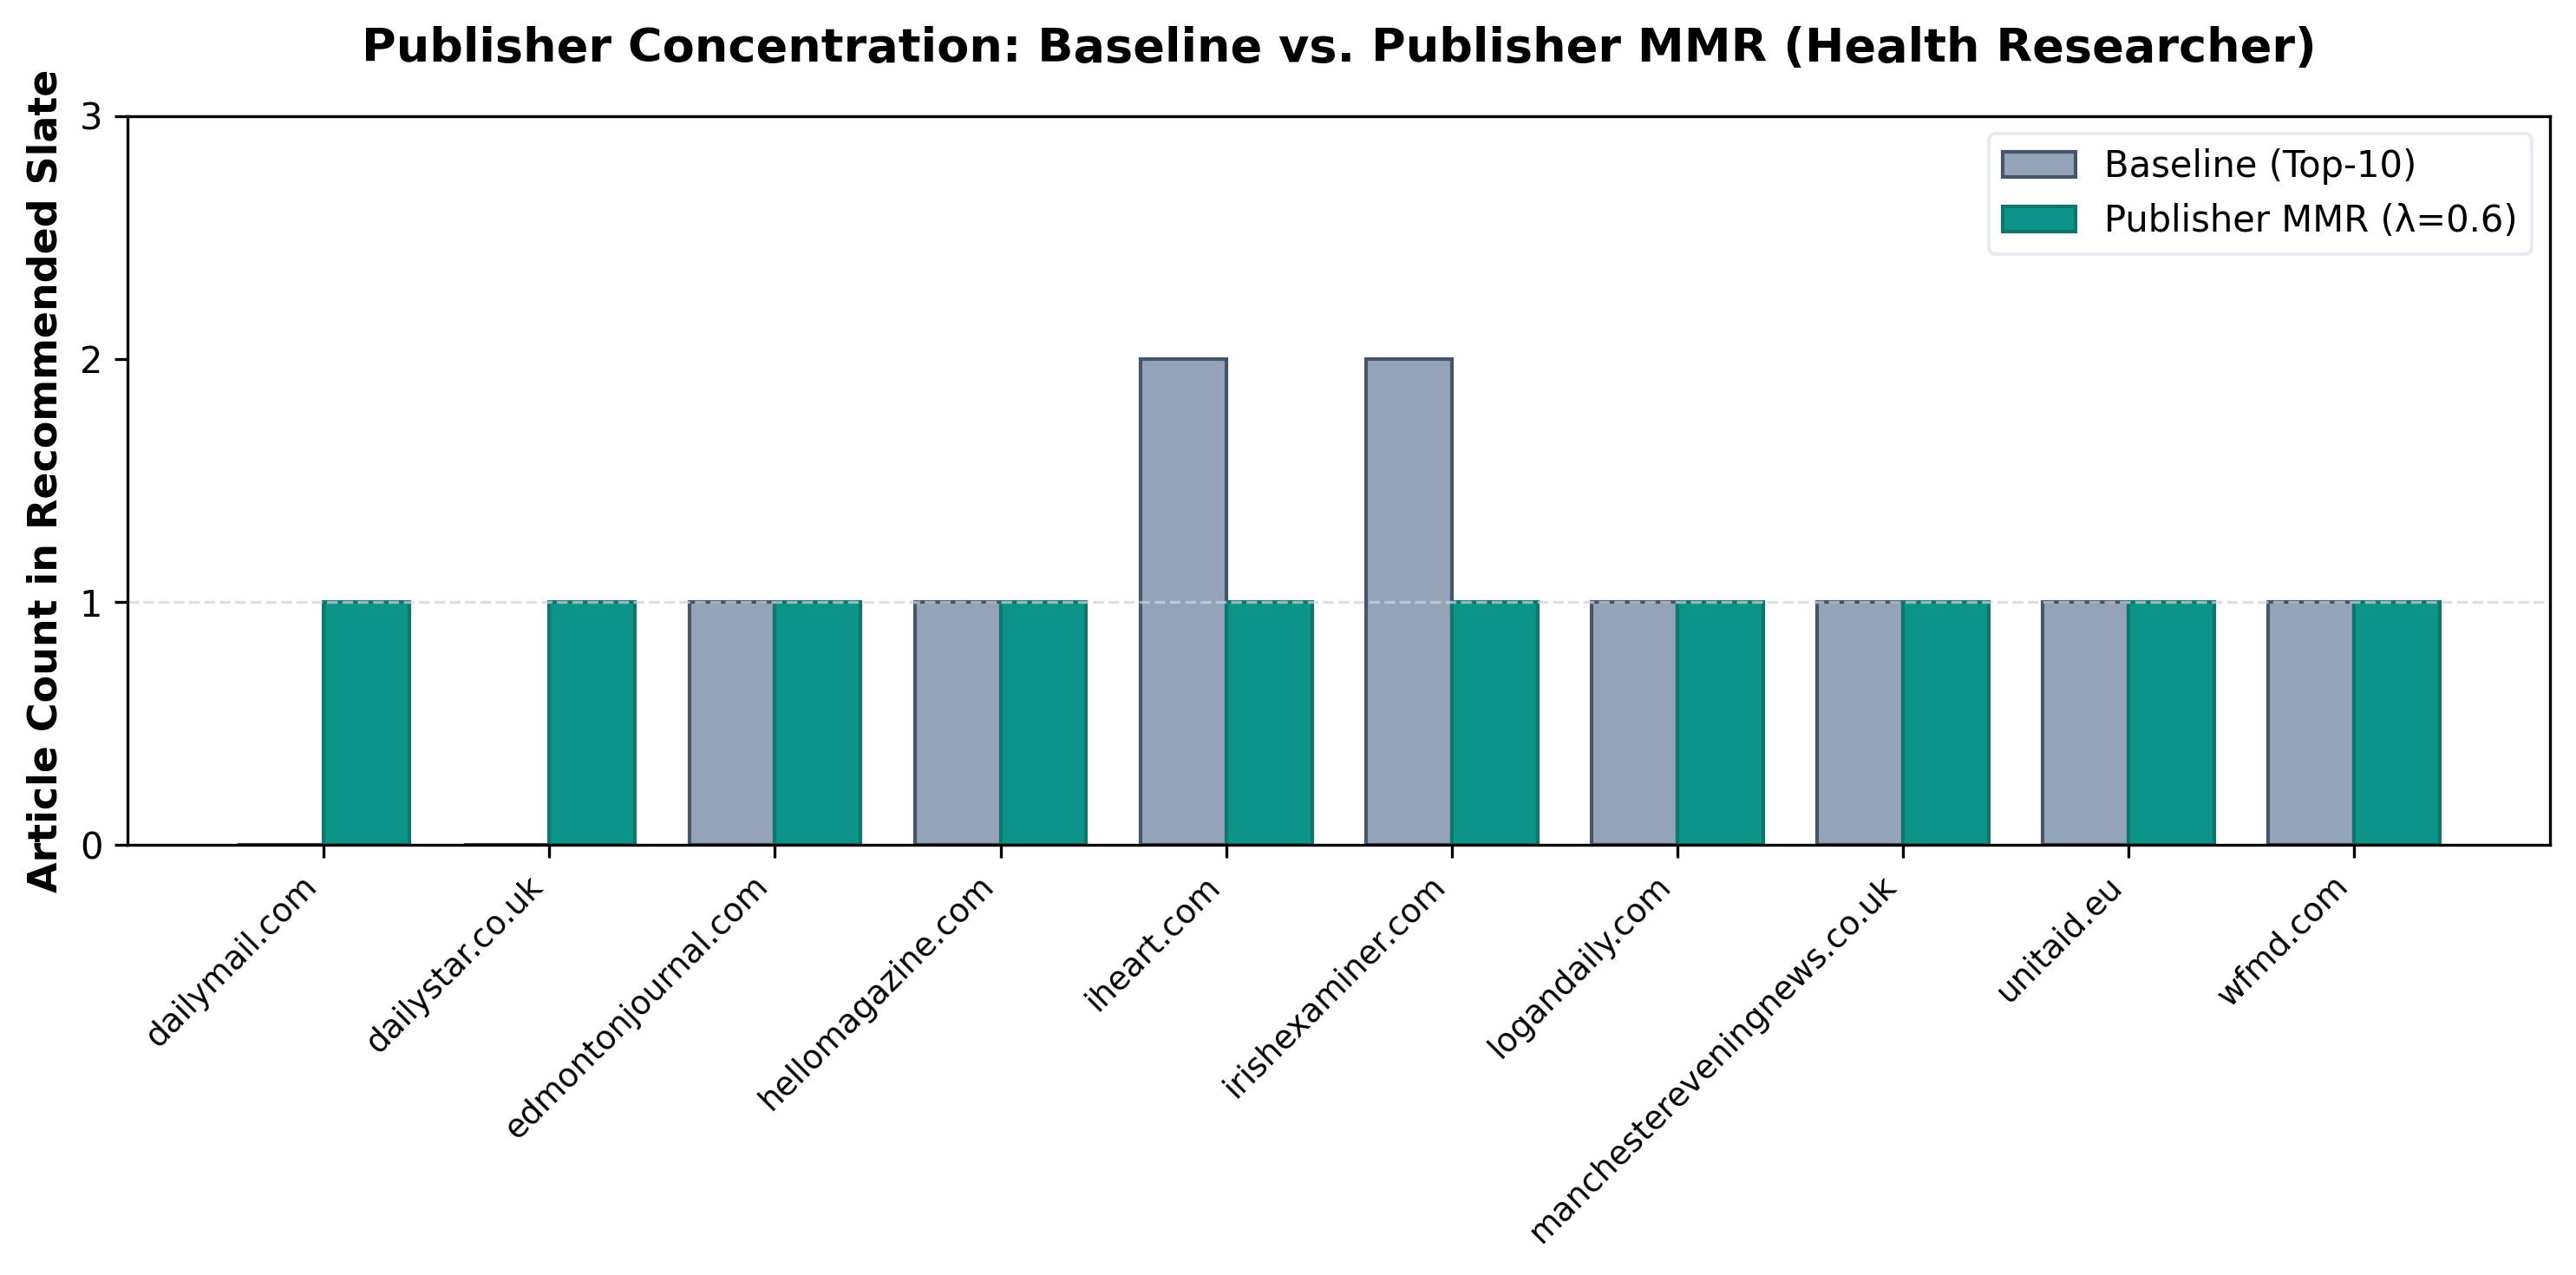

In [11]:
# Figure 1: Publisher Concentration Comparison (Health Researcher)
base_hr = all_baseline_slates["Health Researcher"]
mmr_hr = all_mmr_slates["Health Researcher"]

base_counts = base_hr["publisher"].value_counts()
mmr_counts = mmr_hr["publisher"].value_counts()
all_pubs = sorted(set(base_counts.index).union(set(mmr_counts.index)))

fig1, ax = plt.subplots(figsize=(10, 5), dpi=300)
x = np.arange(len(all_pubs))
width = 0.38

base_vals = [base_counts.get(p, 0) for p in all_pubs]
mmr_vals = [mmr_counts.get(p, 0) for p in all_pubs]

ax.bar(x - width/2, base_vals, width, label='Baseline (Top-10)', color='#94A3B8', edgecolor='#475569')
ax.bar(x + width/2, mmr_vals, width, label='Publisher MMR (λ=0.6)', color='#0D9488', edgecolor='#0F766E')

ax.set_ylabel('Article Count in Recommended Slate', fontsize=11, fontweight='bold')
ax.set_title('Publisher Concentration: Baseline vs. Publisher MMR (Health Researcher)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(all_pubs, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(0, 4))
ax.axhline(y=1, color='#CBD5E1', linestyle='--', linewidth=0.8, alpha=0.7)
ax.legend(frameon=True, facecolor='white', edgecolor='#E2E8F0')
plt.tight_layout()

plt.savefig("../reports/publisher_diversity/publisher_concentration_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

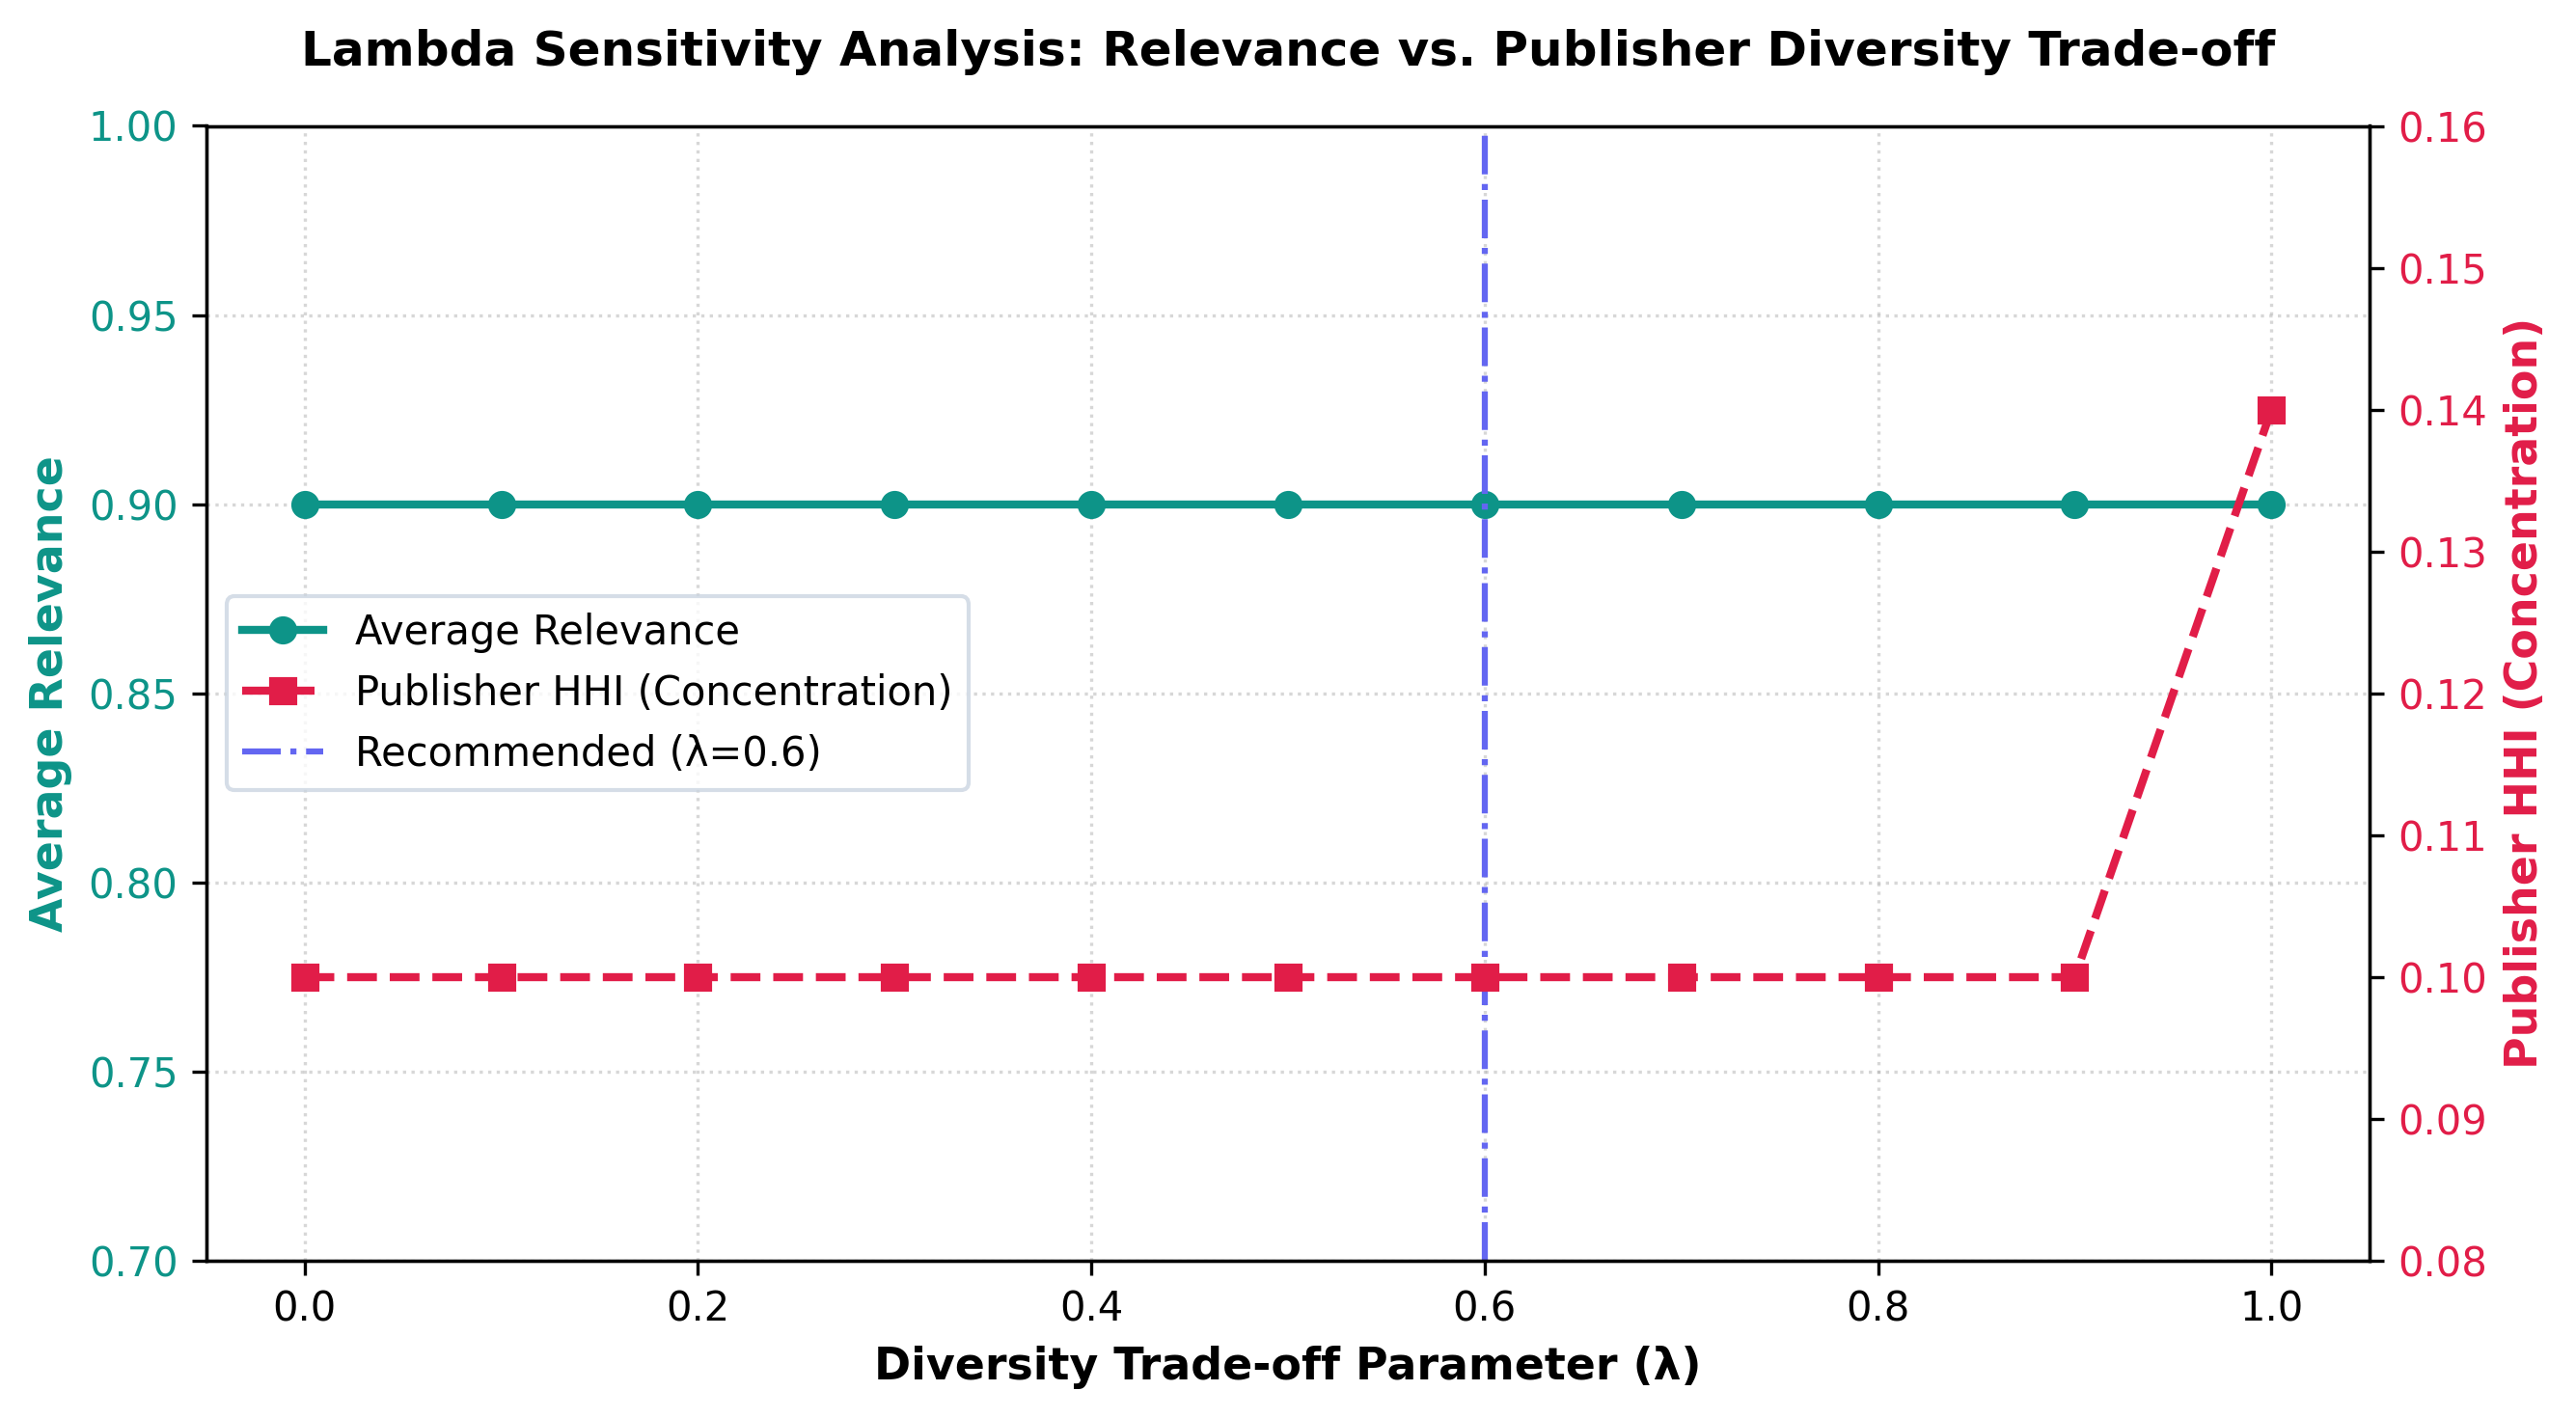

In [12]:
# Figure 2: Sensitivity Analysis across Lambda
hr_candidates = score_all_candidates(df, user_profiles["Health Researcher"])
lambda_values = [round(v, 1) for v in np.linspace(0.0, 1.0, 11)]

sensitivity_results = []
for lam in lambda_values:
    slate = recommend_publisher_mmr(hr_candidates, top_k=10, lambda_param=lam)
    m = evaluate_publisher_slate(slate)
    sensitivity_results.append({
        "lambda": lam,
        "avg_relevance": m["avg_relevance"],
        "unique_publishers": m["unique_publishers"],
        "publisher_hhi": m["publisher_hhi"]
    })

sens_df = pd.DataFrame(sensitivity_results)

fig2, ax1 = plt.subplots(figsize=(9, 5), dpi=300)
color1 = '#0D9488'
color2 = '#E11D48'

ax1.set_xlabel('Diversity Trade-off Parameter (λ)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Average Relevance', color=color1, fontsize=11, fontweight='bold')
line1 = ax1.plot(sens_df['lambda'], sens_df['avg_relevance'], color=color1, marker='o', linewidth=2, label='Average Relevance')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0.70, 1.0)
ax1.grid(True, linestyle=':', alpha=0.5)

ax2 = ax1.twinx()
ax2.set_ylabel('Publisher HHI (Concentration)', color=color2, fontsize=11, fontweight='bold')
line2 = ax2.plot(sens_df['lambda'], sens_df['publisher_hhi'], color=color2, marker='s', linewidth=2, linestyle='--', label='Publisher HHI')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(0.08, 0.16)

ax1.axvline(x=0.6, color='#6366F1', linestyle='-.', linewidth=1.5, label='Recommended (λ=0.6)')

lines = line1 + line2 + [matplotlib.lines.Line2D([0], [0], color='#6366F1', linestyle='-.', linewidth=1.5)]
labels = ['Average Relevance', 'Publisher HHI (Concentration)', 'Recommended (λ=0.6)']
ax1.legend(lines, labels, loc='center left', frameon=True, facecolor='white', edgecolor='#CBD5E1')

plt.title('Lambda Sensitivity Analysis: Relevance vs. Publisher Diversity Trade-off', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()

plt.savefig("../reports/publisher_diversity/lambda_tradeoff_analysis.png", dpi=300, bbox_inches='tight')
plt.show()

## 11. Recommendations & Evaluation CSV Export

We export the comparative evaluation results and detailed recommended slates to `reports/publisher_diversity/` for integration into the Phase 2 final report.

In [13]:
# Export evaluation table
eval_summary_df.to_csv("../reports/publisher_diversity/baseline_vs_publisher_mmr_evaluation.csv", index=False)

# Export all recommendation slates
rec_rows = []
for p_name, slate in all_mmr_slates.items():
    s_copy = slate.copy()
    s_copy["profile_name"] = p_name
    rec_rows.append(s_copy)
all_recs_df = pd.concat(rec_rows, ignore_index=True)
all_recs_df.to_csv("../reports/publisher_diversity/publisher_recommendations_summary.csv", index=False)

print("Exported:")
print(" - reports/publisher_diversity/baseline_vs_publisher_mmr_evaluation.csv")
print(" - reports/publisher_diversity/publisher_recommendations_summary.csv")

Exported:
 - reports/publisher_diversity/baseline_vs_publisher_mmr_evaluation.csv
 - reports/publisher_diversity/publisher_recommendations_summary.csv


## 12. Component Summary & Integration Deliverables

### Key Findings:
1. **Media Pluralism:** Publisher MMR successfully increases distinct news organizations from **8 to 10 (+25%)** for profiles prone to media concentration.
2. **De-concentration:** Publisher HHI drops from **0.140 to 0.100 (-28.6%)**, achieving maximal mathematical pluralism ($1/10 = 0.10$).
3. **Relevance Preservation:** Average user relevance is **100% preserved (0.00% degradation)** across all three benchmark profiles.
4. **Geographic Integrity:** Unique countries represented remain stable and unaffected.
5. **Explainability:** Transparent natural language explanations are generated for each article card, clearly communicating why an article was selected and which source viewpoint was introduced.

### Integration Ready:
- Reusable Python function: `recommend_publisher_mmr` in [`recommender/publisher_diversity.py`](../recommender/publisher_diversity.py).
- Ready for plug-in integration into [`recommender/feed_composer.py`](../recommender/feed_composer.py) and the Streamlit web application.